# DWLR Groundwater Evaluation — Dataset Exploration

This notebook performs an initial exploratory analysis of the January 2026
Dynamic Water Level Recorder (DWLR) dataset.

The objectives are to:

- Understand the structure and coverage of the dataset
- Examine DTWL (Depth to Water Level) distributions
- Analyze spatial coverage
- Identify missing values and duplicate records
- Investigate geographic patterns in groundwater levels
- Identify data-quality issues that should be addressed before modelling

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
DATA_FILE = Path("../data/raw/January_2026.csv")
df = pd.read_csv(DATA_FILE)
df.head()

,STATE_UT,DISTRICT,BLOCK,VILLAGE,LATITUDE,LONGITUDE,DATE,DTWL
0,Andhra Pradesh,Alluri Sitharama Raju,Addateegala,Addateegala,17.4633,82.0271,10-01-2026,7.58
1,Andhra Pradesh,Alluri Sitharama Raju,Addateegala,Mallavaram Mammilu,17.5032,82.0124,10-01-2026,4.21
2,Andhra Pradesh,Alluri Sitharama Raju,Ananthagiri,Kottur,18.2074,83.0743,10-01-2026,3.73
3,Andhra Pradesh,Alluri Sitharama Raju,Araku Valley,Araku,18.3207,82.8814,10-01-2026,4.55
4,Andhra Pradesh,Alluri Sitharama Raju,Araku Valley,Aruku,18.3250,82.8793,10-01-2026,7.93


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 16952
Columns: 8


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16952 entries, 0 to 16951
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATE_UT   16952 non-null  str    
 1   DISTRICT   16952 non-null  str    
 2   BLOCK      15385 non-null  str    
 3   VILLAGE    14883 non-null  str    
 4   LATITUDE   16952 non-null  float64
 5   LONGITUDE  16952 non-null  float64
 6   DATE       16952 non-null  str    
 7   DTWL       16952 non-null  float64
dtypes: float64(3), str(5)
memory usage: 1.0 MB


In [5]:
df.describe()

,LATITUDE,LONGITUDE,DTWL
count,16952.000000,16952.000000,16952.000000
mean,21.485442,78.702395,8.074352
std,5.735373,5.213860,11.416818
min,8.083330,68.520300,0.010000
25%,18.498520,75.125150,2.650000
50%,22.347100,77.305010,4.500000
75%,25.652785,81.883330,7.950000
max,33.769300,96.133330,98.880000


In [6]:
missing = df.isnull().sum()
missing_percentage = (missing / len(df)) * 100
missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percentage
})
missing_summary

,Missing Values,Percentage
STATE_UT,0,0.000000
DISTRICT,0,0.000000
BLOCK,1567,9.243747
VILLAGE,2069,12.205050
LATITUDE,0,0.000000
LONGITUDE,0,0.000000
DATE,0,0.000000
DTWL,0,0.000000


In [7]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 5


In [8]:
df["DATE"] = pd.to_datetime(df["DATE"])

print("Earliest date:", df["DATE"].min())
print("Latest date:", df["DATE"].max())
print("Unique dates:", df["DATE"].nunique())

Earliest date: 2026-10-01 00:00:00
Latest date: 2026-10-01 00:00:00
Unique dates: 1


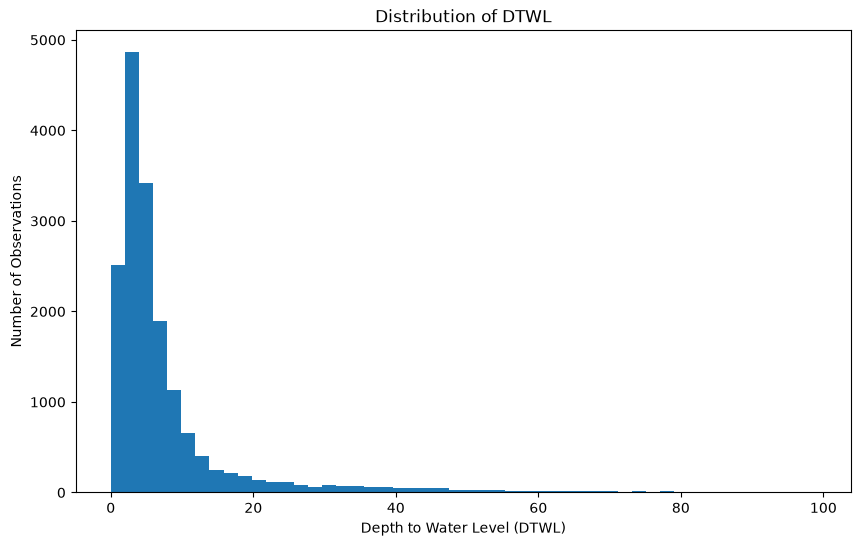

In [9]:
plt.figure(figsize=(10, 6))
plt.hist(df["DTWL"], bins=50)
plt.xlabel("Depth to Water Level (DTWL)")
plt.ylabel("Number of Observations")
plt.title("Distribution of DTWL")
plt.show()

C:\Users\aishw\AppData\Local\Temp\ipykernel_31644\2220990028.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["DTWL"].dropna(), vert=False)


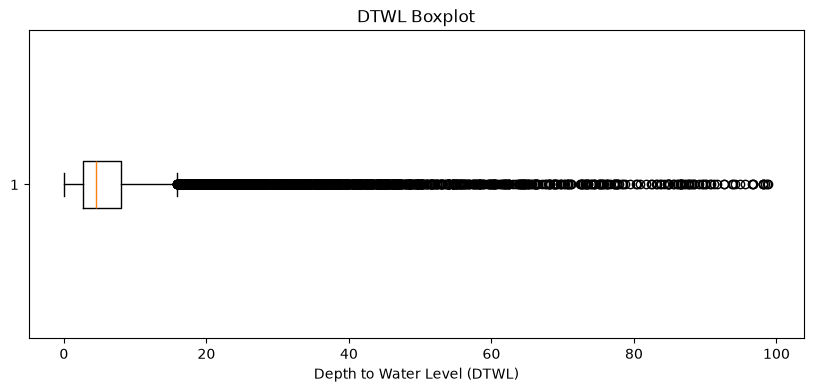

In [10]:
plt.figure(figsize=(10, 4))
plt.boxplot(df["DTWL"].dropna(), vert=False)
plt.xlabel("Depth to Water Level (DTWL)")
plt.title("DTWL Boxplot")
plt.show()

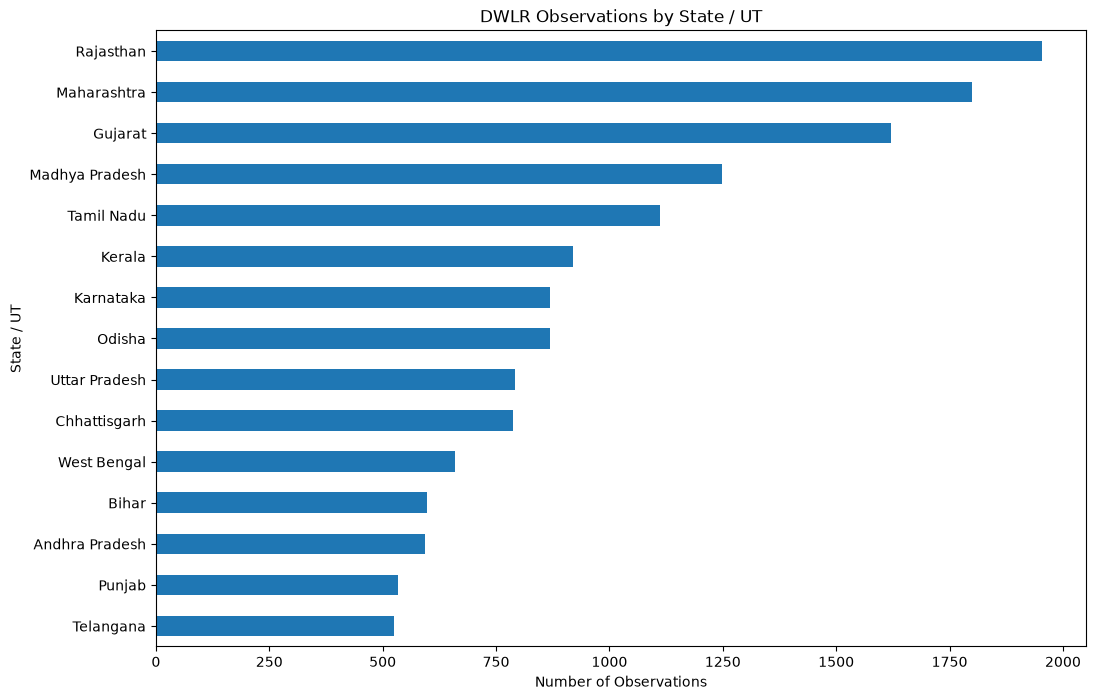

In [11]:
state_counts = df["STATE_UT"].value_counts()
plt.figure(figsize=(12, 8))
state_counts.head(15).sort_values().plot(kind="barh")
plt.xlabel("Number of Observations")
plt.ylabel("State / UT")
plt.title("DWLR Observations by State / UT")
plt.show()

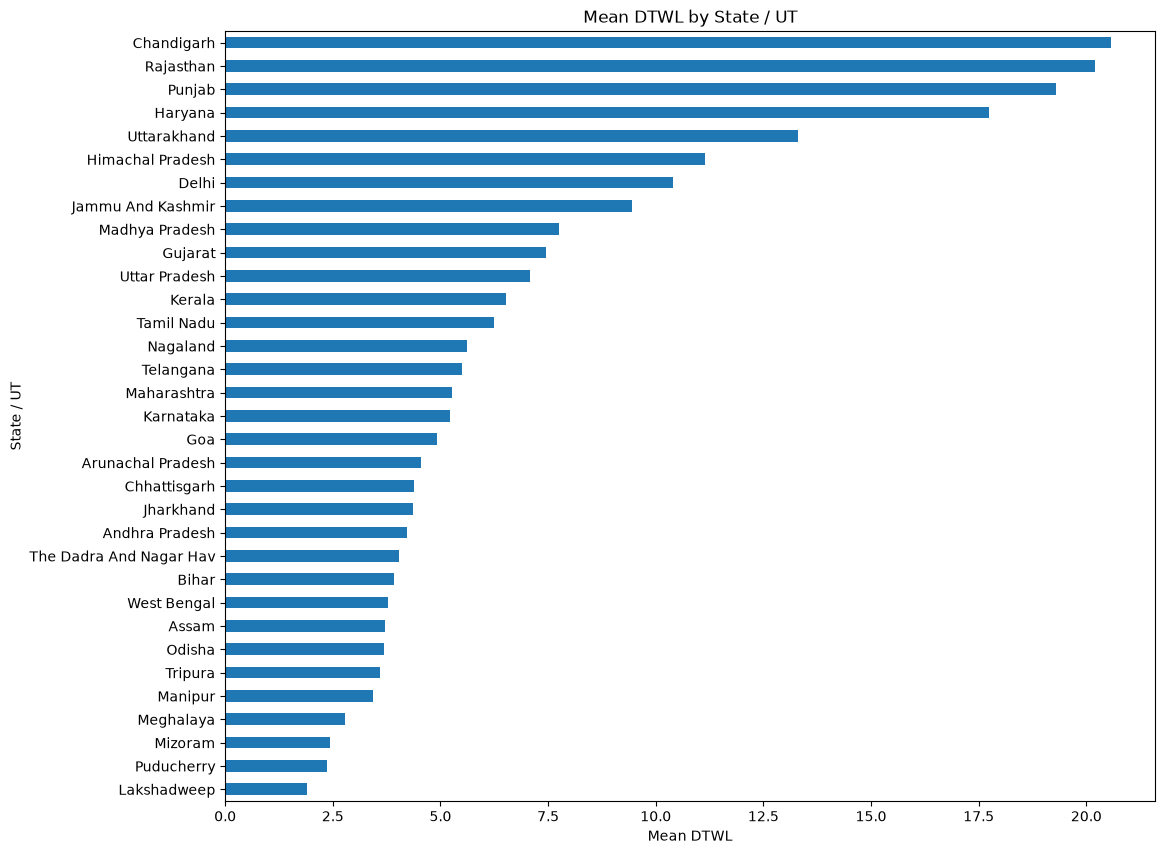

In [12]:
state_dtwl = (
    df.groupby("STATE_UT")["DTWL"]
    .mean()
    .sort_values()
)
plt.figure(figsize=(12, 10))
state_dtwl.plot(kind="barh")
plt.xlabel("Mean DTWL")
plt.ylabel("State / UT")
plt.title("Mean DTWL by State / UT")
plt.show()

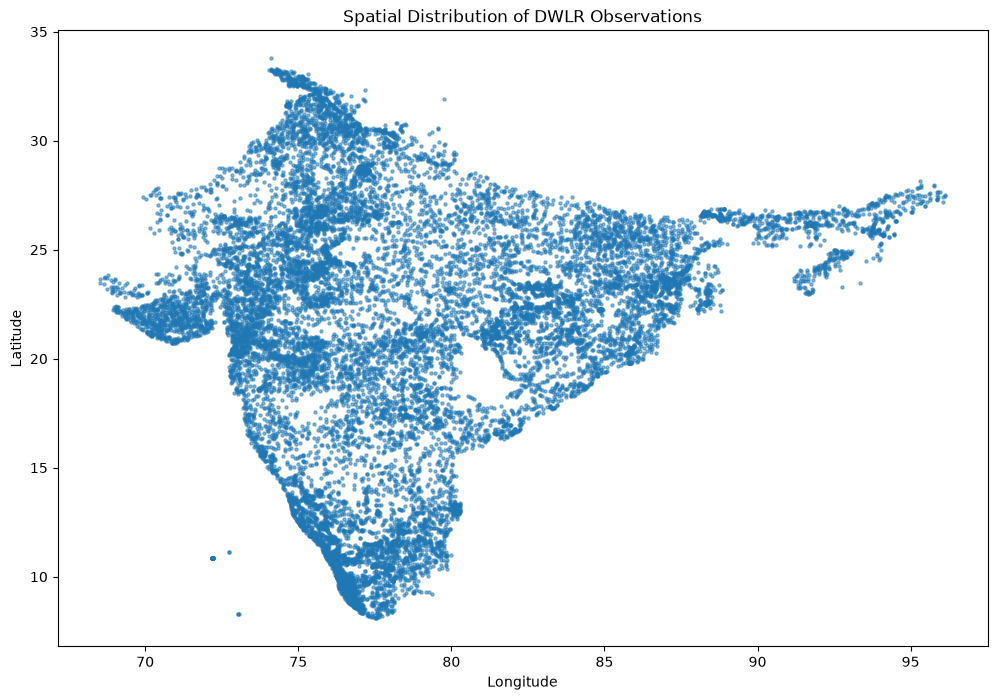

In [13]:
plt.figure(figsize=(12, 8))

plt.scatter(
    df["LONGITUDE"],
    df["LATITUDE"],
    s=5,
    alpha=0.5
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of DWLR Observations")

plt.show()

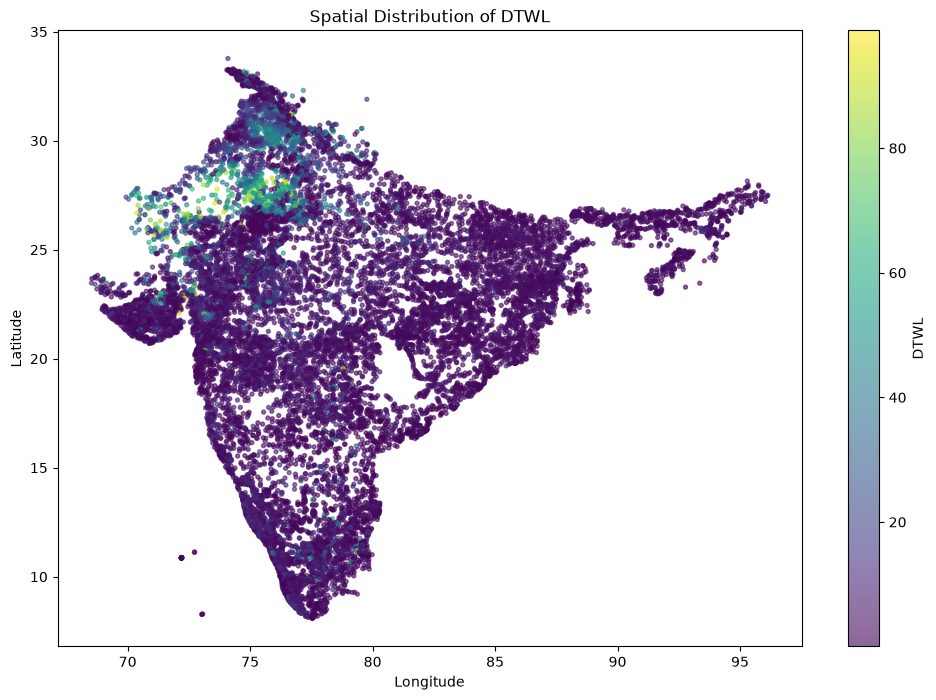

In [14]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    df["LONGITUDE"],
    df["LATITUDE"],
    c=df["DTWL"],
    s=8,
    alpha=0.6
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of DTWL")

plt.colorbar(scatter, label="DTWL")

plt.show()

In [15]:
district_counts = (
    df["DISTRICT"]
    .value_counts()
    .reset_index()
)

district_counts.columns = ["District", "Count"]

district_counts.head(30)

district_lower = (
    df["DISTRICT"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print("Original unique districts:", df["DISTRICT"].nunique())
print("Case-normalized unique districts:", district_lower.nunique())

Original unique districts: 800
Case-normalized unique districts: 727


## Initial Observations

The January 2026 DWLR dataset contains 16,952 observations across 33
States/UTs and 800 districts.

The dataset contains observations for a single date, making it a spatial
snapshot rather than a temporal series.

DTWL has a mean of approximately 8.07 and a median of 4.50, indicating a
right-skewed distribution with some observations having substantially greater
depth to water level.

BLOCK and VILLAGE contain missing values, while latitude, longitude, date,
and DTWL do not contain missing values.

The dataset also contains a small number of exact duplicate records and
district naming inconsistencies that should be investigated during the
data-cleaning stage.

Spatial coverage is uneven across States/UTs, which should be considered
when performing geographic comparisons.